# Preprocessing and Baseline Models

## Evaluation design

- **Split:** train 2001–2014 (3,142 companies), validation 2015 (233), test 2016–2018 (2,815). The model learns from earlier years and is checked on later ones, so it never learns from the future.
- **Metrics:** PR-AUC is the main metric, because bankruptcies are rare. ROC-AUC, precision, recall and F1 are also reported. Accuracy is misleading, because always predicting "healthy" scores 88%.
- Each company appears only in one split, so the model is never tested on a company it was trained on.
- The test set is not used. It will be used once at the very end.

In [1]:
import pandas as pd

train = pd.read_csv("../data/raw/financial_train.csv")
validation = pd.read_csv("../data/raw/financial_validation.csv")

print("Train:", train.shape)
print("Validation:", validation.shape)

Train: (3142, 57)
Validation: (233, 57)


In [2]:
y_train = (train["status_label"] == "failed").astype(int)
y_val = (validation["status_label"] == "failed").astype(int)

print("Bankruptcies in train:", y_train.sum())
print("Bankruptcies in validation:", y_val.sum())

Bankruptcies in train: 403
Bankruptcies in validation: 27


In [3]:
def make_ratios(data):
    ratios = pd.DataFrame()
    ratios["Liquidity"] = (data["3_current_assets"] - data["3_total_current_liabilities"]) / data["3_total_assets"]
    ratios["Retained_Earnings"] = data["3_retained_earnings"] / data["3_total_assets"]
    ratios["Operating_Profitability"] = data["3_ebit"] / data["3_total_assets"]
    ratios["Solvency"] = data["3_market_value"] / data["3_total_liabilities"]
    ratios["Asset_Turnover"] = data["3_net_sales"] / data["3_total_assets"]
    return ratios

X_train = make_ratios(train)
X_val = make_ratios(validation)

X_train.describe()

,Liquidity,Retained_Earnings,Operating_Profitability,Solvency,Asset_Turnover
count,3142.000000,3142.000000,3142.000000,3142.000000,3142.000000
mean,-2.894015,-19.000515,-0.722135,65.777239,1.418761
std,80.443946,343.066209,17.783871,3358.927836,6.868612
min,-3800.375000,-14683.000000,-954.000000,0.000009,-0.012243
25%,-0.025314,-2.175448,-0.164898,0.384663,0.535992
50%,0.171719,-0.309814,0.013001,1.372328,0.968990
75%,0.390563,0.140147,0.082117,4.006652,1.614102
max,0.990368,2.246770,5.175334,188244.000000,365.000000


In [4]:
lower = X_train.quantile(0.01)
upper = X_train.quantile(0.99)

X_train = X_train.clip(lower, upper, axis=1)
X_val = X_val.clip(lower, upper, axis=1)

X_train.describe()

,Liquidity,Retained_Earnings,Operating_Profitability,Solvency,Asset_Turnover
count,3142.000000,3142.000000,3142.000000,3142.000000,3142.000000
mean,-0.106370,-4.789467,-0.218796,3.738083,1.232657
std,1.625302,16.656191,0.827906,6.525254,1.023653
min,-12.599955,-125.733832,-6.047169,0.003009,0.009211
25%,-0.025314,-2.175448,-0.164898,0.384663,0.535992
50%,0.171719,-0.309814,0.013001,1.372328,0.968990
75%,0.390563,0.140147,0.082117,4.006652,1.614102
max,0.860585,0.826159,0.344142,41.902291,5.447371


## Preprocessing

- **Features:** five ratios of the Altman Z-score, a model for predicting corporate bankruptcy: Liquidity, Retained Earnings, Operating Profitability, Solvency and Asset Turnover. The logistic regression learns its own weights from the data. All ratios use the company's most recent year of accounts.

- **Clipping:** extreme values capped at the 1st and 99th percentiles of the training data, to limit a few extreme values (e.g. solvency ratio of 188,244).
- **Scaling:** done inside the pipeline with `StandardScaler`, fitted on training data only.
- **Class imbalance:** logistic regression uses `class_weight="balanced"` so it does not ignore the rare bankrupt class.

## Majority-class Model

In [5]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, recall_score

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_val)

print("Accuracy:", round(accuracy_score(y_val, baseline_pred), 3))
print("Recall:", round(recall_score(y_val, baseline_pred), 3))

Accuracy: 0.884
Recall: 0.0


## Logistic Regression

In [6]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

model = Pipeline([
    ("scale", StandardScaler()),
    ("logreg", LogisticRegression(class_weight="balanced", max_iter=1000))
])

model.fit(X_train, y_train)

val_prob = model.predict_proba(X_val)[:, 1]
val_pred = model.predict(X_val)

print("Accuracy:", round(accuracy_score(y_val, val_pred), 3))
print("Recall:", round(recall_score(y_val, val_pred), 3))

Accuracy: 0.532
Recall: 0.963


In [7]:
from sklearn.metrics import precision_score, f1_score, average_precision_score, roc_auc_score

baseline_prob = baseline.predict_proba(X_val)[:, 1]

results = pd.DataFrame({
    "Majority class": [
        average_precision_score(y_val, baseline_prob),
        roc_auc_score(y_val, baseline_prob),
        precision_score(y_val, baseline_pred, zero_division=0),
        recall_score(y_val, baseline_pred),
        f1_score(y_val, baseline_pred),
    ],
    "Logistic regression": [
        average_precision_score(y_val, val_prob),
        roc_auc_score(y_val, val_prob),
        precision_score(y_val, val_pred),
        recall_score(y_val, val_pred),
        f1_score(y_val, val_pred),
    ],
}, index=["PR-AUC", "ROC-AUC", "Precision", "Recall", "F1"])

results.round(3)

,Majority class,Logistic regression
PR-AUC,0.116,0.259
ROC-AUC,0.500,0.788
Precision,0.000,0.194
Recall,0.000,0.963
F1,0.000,0.323


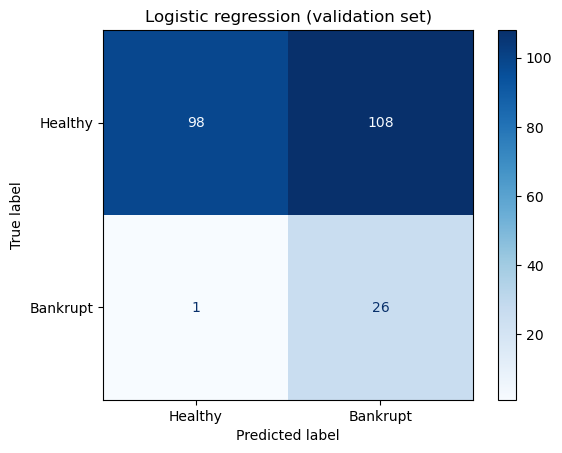

In [8]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(y_val, val_pred, display_labels=["Healthy", "Bankrupt"], cmap="Blues")
plt.title("Logistic regression (validation set)")
plt.show()

## Baseline results

The majority-class model scores 88% accuracy but catches no bankruptcies, which shows why accuracy is misleading.

Logistic regression is clearly better. PR-AUC is 0.259 against 0.116 for no skill, and ROC-AUC is 0.788. At the 0.5 cut-off it catches 26 of the 27 bankruptcies (recall 0.96), but raises 108 false alarms (precision 0.19). It favours catching bankruptcies over avoiding false alarms.

The validation set is small (27 bankruptcies), so these numbers are uncertain. The next step is to test whether more flexible models can improve precision without losing recall.
